# Итоги лабораторных работ №1–5
## Сравнение моделей классификации и регрессии

Сводный отчёт по [KNN](research-1.ipynb), [логистической и линейной регрессии](research-2.ipynb), [решающим деревьям](research-3.ipynb), [случайному лесу](research-4.ipynb) и [градиентному бустингу](research-5.ipynb).

Все таблицы, графики и численные выводы ниже вычисляются из `results/research-1/`–`results/research-5/`. Модели повторно не обучаются, исходные файлы не изменяются, дополнительные CSV не создаются. При изменении результатов лабораторных достаточно выполнить этот ноутбук заново. Зависимости — существующий `requirements.txt`; запускать из корня проекта. Если CSV отсутствуют, сначала выполните соответствующие `research-1.ipynb`–`research-5.ipynb`.

### Условия сравнения

В исходных работах используются одинаковые данные и разбиения с seed=42:
- Steam: 6400 обучающих и 1600 тестовых строк, 20% положительного класса `hit`. Основная метрика — **AP**; дополнительные — F1, precision, recall, balanced accuracy, ROC AUC и accuracy. Метрики по классам используют порог вероятности >0.5, при равенстве выбирается 0.
- Продажи игр: 13272 обучающих и 3326 тестовых строк, цель `global_sales` в **миллионах копий**. Разбиения train/test и CV разделяют версии одной игры по нормализованному названию. Основная метрика — **MAE**, дополнительные — RMSE и R².
- Подготовка и гиперпараметры выбираются на 3-fold CV внутри train; тест используется после фиксации выбора. Сетки и состав проверенных признаков различаются между работами, поэтому сравниваются конкретные исследованные конфигурации.

В классификации больше — лучше; для MAE и RMSE меньше — лучше, для R² больше — лучше. Значение `improved` означает выбранную по CV конфигурацию соответствующей работы, а не обещание улучшить каждую метрику. Самостоятельным моделям NumPy передаются техники и параметры выбранных sklearn-моделей.

### Загрузка результатов и проверка структуры
Читаем 10 CSV: тестовые метрики и сводку CV каждой работы. В первом файле CV колонка `selection_score` переименовывается в общий `score` только в памяти. Проверяем полноту комбинаций задача–модель и допустимые диапазоны метрик. NaN в неприменимых столбцах нормальны: AP не относится к регрессии, MAE — к классификации.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd()
RESULTS = ROOT / "results"
NAMES = {
    1: {"c": "KNN", "r": "KNN"},
    2: {"c": "Логистическая регрессия", "r": "Линейная регрессия / Ridge"},
    3: {"c": "Решающее дерево", "r": "Решающее дерево"},
    4: {"c": "Случайный лес", "r": "Случайный лес"},
    5: {"c": "Градиентный бустинг", "r": "Градиентный бустинг"}
}
MODELS = {"Dummy", "sklearn baseline", "sklearn improved", "numpy baseline", "numpy improved"}
class_metrics = ["AP", "F1", "Precision", "Recall", "Balanced_accuracy", "ROC_AUC", "Accuracy"]
metric_parts, cv_parts, source_rows = [], [], []
for lab in range(1, 6):
    folder = RESULTS / f"research-{lab}"
    paths = [folder / "test_metrics.csv", folder / "cv_experiments.csv"]
    missing = [str(p.relative_to(ROOT)) for p in paths if not p.is_file()]
    if missing:
        raise FileNotFoundError("Сначала выполните соответствующие лабораторные: " + ", ".join(missing))
    test = pd.read_csv(paths[0])
    cv = pd.read_csv(paths[1]).rename(columns={"selection_score": "score"})
    assert len(test) == 10 and not test.duplicated(["task", "model"]).any()
    assert set(test.task) == set(cv.task) == {"c", "r"}
    for task in ["c", "r"]:
        assert set(test.loc[test.task == task, "model"]) == MODELS
    assert np.isfinite(test.loc[test.task == "c", class_metrics]).all().all()
    assert test.loc[test.task == "c", class_metrics].apply(lambda x: x.between(0, 1)).all().all()
    regression = test.loc[test.task == "r", ["MAE", "RMSE", "R2"]]
    assert np.isfinite(regression).all().all()
    assert (regression.MAE >= 0).all() and (regression.RMSE >= regression.MAE-1e-10).all()
    assert (regression.R2 <= 1+1e-10).all()
    assert np.isfinite(cv[["score", "std"]]).all().all() and (cv["std"] >= 0).all()
    assert cv.loc[cv.task == "c", "score"].between(0, 1).all()
    assert (cv.loc[cv.task == "r", "score"] <= 0).all()
    for frame in [test, cv]:
        frame["lab"] = lab
        frame["algorithm"] = frame.task.map(NAMES[lab])
    metric_parts.append(test)
    cv_parts.append(cv)
    for path, frame in zip(paths, [test, cv]):
        source_rows.append({"Работа": lab, "Источник": str(path.relative_to(ROOT)), "Строк": len(frame)})
metrics = pd.concat(metric_parts, ignore_index=True)
cv_results = pd.concat(cv_parts, ignore_index=True)
models = metrics.loc[metrics.model != "Dummy"].copy()
models["implementation"] = models.model.str.split().str[0]
models["stage"] = models.model.str.split().str[1]
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_colwidth", 65)
display(pd.DataFrame(source_rows))
print("Загружено:", len(metrics), "строк тестовых метрик и", len(cv_results), "строк CV. Проверки пройдены.")

,Работа,Источник,Строк
0,1,results/research-1/test_metrics.csv,10
1,1,results/research-1/cv_experiments.csv,9
2,2,results/research-2/test_metrics.csv,10
3,2,results/research-2/cv_experiments.csv,8
4,3,results/research-3/test_metrics.csv,10
5,3,results/research-3/cv_experiments.csv,9
6,4,results/research-4/test_metrics.csv,10
7,4,results/research-4/cv_experiments.csv,9
8,5,results/research-5/test_metrics.csv,10
9,5,results/research-5/cv_experiments.csv,9


Загружено: 50 строк тестовых метрик и 44 строк CV. Проверки пройдены.


## 1. Классификация: улучшенные модели sklearn
Ранжируем по основной метрике AP; остальные метрики показывают поведение фиксированного порога. Значения Dummy должны совпадать между работами, поскольку тест одинаковый. Его accuracy=0.8 достигается выбором класса большинства при нулевой F1 положительного класса.

In [2]:
classification = models.query("task == 'c' and implementation == 'sklearn' and stage == 'improved'").sort_values("AP", ascending=False)
display(classification[["lab", "algorithm"] + class_metrics].round(4).reset_index(drop=True))
dummy_c = metrics.query("task == 'c' and model == 'Dummy'")
np.testing.assert_allclose(dummy_c[class_metrics], np.repeat(dummy_c[class_metrics].iloc[[0]].to_numpy(), 5, axis=0))
display(dummy_c.iloc[[0]][["model"] + class_metrics].round(4))
leader = classification.iloc[0]
display(Markdown(f"**Лидер sklearn по AP на этом тесте:** {leader.algorithm} — "
                 f"AP={leader.AP:.4f}, F1={leader.F1:.4f}, ROC AUC={leader.ROC_AUC:.4f}. "
                 "Различия на одном holdout не доказывают статистическую значимость и общее превосходство алгоритма."))

,lab,algorithm,AP,F1,Precision,Recall,Balanced_accuracy,ROC_AUC,Accuracy
0,2,Логистическая регрессия,0.7208,0.6328,0.5085,0.8375,0.8176,0.9030,0.8056
1,4,Случайный лес,0.7176,0.6321,0.5009,0.8562,0.8215,0.9016,0.8006
2,5,Градиентный бустинг,0.7130,0.6104,0.7173,0.5312,0.7395,0.9005,0.8644
3,3,Решающее дерево,0.6697,0.6102,0.4740,0.8562,0.8094,0.8852,0.7812
4,1,KNN,0.6680,0.4990,0.7453,0.3750,0.6715,0.8775,0.8494


,model,AP,F1,Precision,Recall,Balanced_accuracy,ROC_AUC,Accuracy
0,Dummy,0.2,0.0,0.0,0.0,0.5,0.5,0.8


**Лидер sklearn по AP на этом тесте:** Логистическая регрессия — AP=0.7208, F1=0.6328, ROC AUC=0.9030. Различия на одном holdout не доказывают статистическую значимость и общее превосходство алгоритма.

### Исходные и улучшенные классификаторы
График показывает изменение AP после выбранных в каждой работе улучшений. Более высокая AP не гарантирует роста accuracy, precision или recall одновременно: это разные свойства модели.

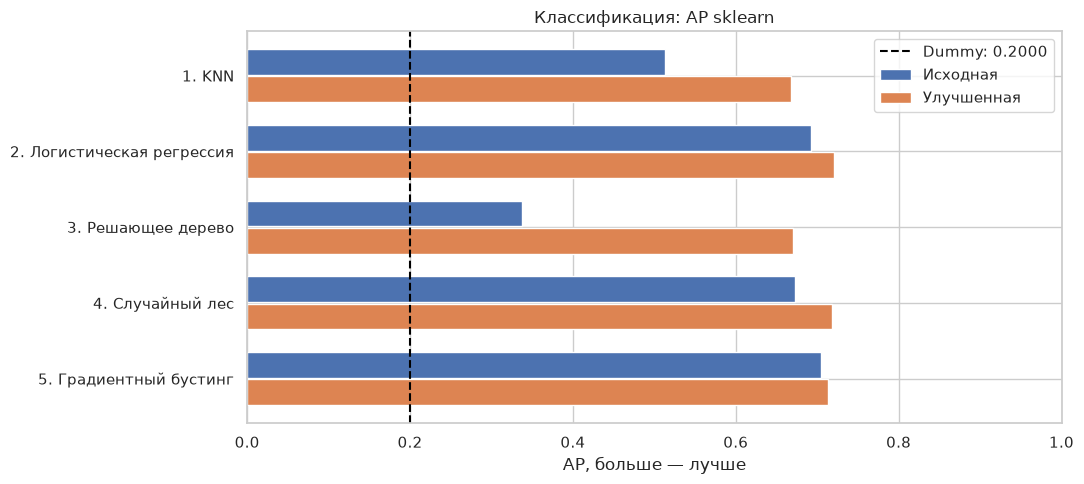

stage,baseline,improved,gain_AP
lab,,,
1,0.5132,0.6680,0.1549
2,0.6929,0.7208,0.0280
3,0.3370,0.6697,0.3327
4,0.6722,0.7176,0.0453
5,0.7042,0.7130,0.0088


**Наибольший прирост AP:** Решающее дерево — +0.3327. В третьей работе исходное дерево имело train AP=1 при существенно более низкой тестовой AP: ограничение сложности проверялось для уменьшения переобучения.

In [3]:
def compare_stages(task, metric, ax, title, xlabel):
    subset = models.query("task == @task and implementation == 'sklearn'")
    pivot = subset.pivot(index="lab", columns="stage", values=metric).reindex(range(1, 6))
    labels = [f"{lab}. {NAMES[lab][task]}" for lab in pivot.index]
    positions = np.arange(len(pivot))
    ax.barh(positions-.18, pivot["baseline"], height=.34, label="Исходная")
    ax.barh(positions+.18, pivot["improved"], height=.34, label="Улучшенная")
    dummy = metrics.loc[(metrics.task == task) & (metrics.model == "Dummy"), metric].iloc[0]
    ax.axvline(dummy, color="black", linestyle="--", label=f"Dummy: {dummy:.4f}")
    ax.set_yticks(positions, labels)
    ax.invert_yaxis()
    ax.set(title=title, xlabel=xlabel)
    ax.legend()
    return pivot
fig, ax = plt.subplots(figsize=(11, 5))
class_stages = compare_stages("c", "AP", ax, "Классификация: AP sklearn", "AP, больше — лучше")
ax.set_xlim(0, 1)
plt.tight_layout(); plt.show()
class_stages["gain_AP"] = class_stages.improved-class_stages.baseline
display(class_stages.round(4))
best_gain_lab = int(class_stages.gain_AP.idxmax())
display(Markdown(f"**Наибольший прирост AP:** {NAMES[best_gain_lab]['c']} — "
                 f"{class_stages.loc[best_gain_lab, 'gain_AP']:+.4f}. "
                 "В третьей работе исходное дерево имело train AP=1 при существенно более низкой тестовой AP: "
                 "ограничение сложности проверялось для уменьшения переобучения."))

## 2. Регрессия: улучшенные модели sklearn
MAE и RMSE — в миллионах копий, R² безразмерный. Отрицательный R² допустим и означает результат хуже предсказания среднего тестовой цели по квадратам ошибок. Dummy здесь предсказывает медиану train, оптимальную для MAE, поэтому его R² не обязан быть равен нулю.

Сравнение с Dummy отделяет выигрыш относительно слабого исходного алгоритма от преимущества над простым постоянным прогнозом.

In [4]:
regression = models.query("task == 'r' and implementation == 'sklearn' and stage == 'improved'").sort_values("MAE")
dummy_r = metrics.query("task == 'r' and model == 'Dummy'")
np.testing.assert_allclose(dummy_r[["MAE", "RMSE", "R2"]], np.repeat(dummy_r[["MAE", "RMSE", "R2"]].iloc[[0]].to_numpy(), 5, axis=0))
dummy_mae = float(dummy_r.MAE.iloc[0])
regression = regression.assign(gain_vs_dummy=dummy_mae-regression.MAE,
                               gain_vs_dummy_pct=100*(dummy_mae-regression.MAE)/dummy_mae)
display(regression[["lab", "algorithm", "MAE", "RMSE", "R2", "gain_vs_dummy", "gain_vs_dummy_pct"]].round(4).reset_index(drop=True))
display(dummy_r.iloc[[0]][["model", "MAE", "RMSE", "R2"]].round(4))
leader = regression.iloc[0]
display(Markdown(f"**Лидер sklearn по MAE:** {leader.algorithm} — {leader.MAE:.4f} млн копий; "
                 f"выигрыш относительно Dummy {leader.gain_vs_dummy_pct:.2f}%. "
                 f"R² улучшенных моделей находится в диапазоне {regression.R2.min():.3f}–{regression.R2.max():.3f}: "
                 "объясняющая способность прогноза продаж остаётся ограниченной."))
for row in regression.itertuples():
    if row.gain_vs_dummy <= 0:
        display(Markdown(f"**{row.algorithm} не превзошёл Dummy по MAE:** {row.MAE:.6f} против {dummy_mae:.6f}."))

,lab,algorithm,MAE,RMSE,R2,gain_vs_dummy,gain_vs_dummy_pct
0,4,Случайный лес,0.4383,1.4957,0.1002,0.0179,3.9270
1,3,Решающее дерево,0.4450,1.5048,0.0893,0.0112,2.4582
2,2,Линейная регрессия / Ridge,0.4468,1.4993,0.0958,0.0094,2.0563
3,5,Градиентный бустинг,0.4486,1.5111,0.0816,0.0076,1.6729
4,1,KNN,0.4565,1.5109,0.0819,-0.0003,-0.0732


,model,MAE,RMSE,R2
1,Dummy,0.4562,1.6167,-0.0513


**Лидер sklearn по MAE:** Случайный лес — 0.4383 млн копий; выигрыш относительно Dummy 3.93%. R² улучшенных моделей находится в диапазоне 0.082–0.100: объясняющая способность прогноза продаж остаётся ограниченной.

**KNN не превзошёл Dummy по MAE:** 0.456519 против 0.456185.

### MAE и RMSE до и после улучшений
Выбор по MAE не равнозначен выбору по RMSE. В исходных работах все выбранные улучшенные регрессии используют log1p цели и обратный expm1: это снижает влияние блокбастеров при обучении и меняет центр прогноза. В тесте медиана продаж — 0.17 млн, максимум — 33 млн; редкие крупные ошибки могут сильно влиять на RMSE.

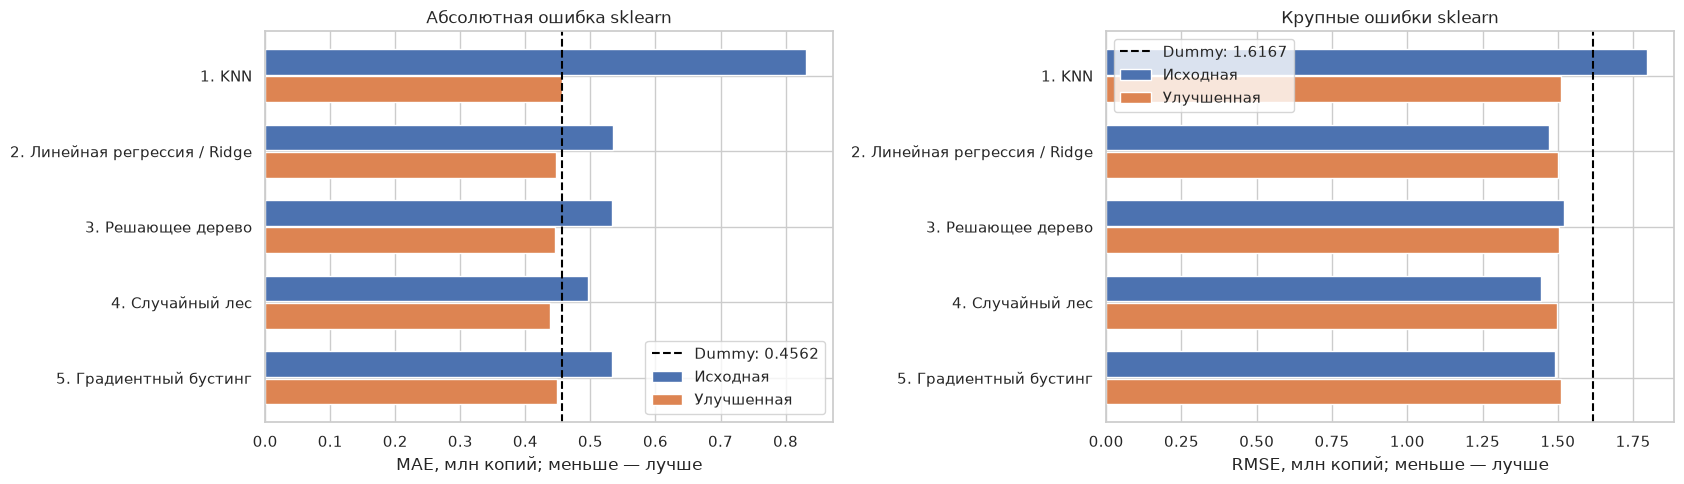

,algorithm,MAE baseline,MAE improved,gain MAE,RMSE baseline,RMSE improved,gain RMSE
1,KNN,0.8314,0.4565,0.3749,1.7960,1.5109,0.2852
2,Линейная регрессия / Ridge,0.5348,0.4468,0.0880,1.4714,1.4993,-0.0280
3,Решающее дерево,0.5333,0.4450,0.0884,1.5216,1.5048,0.0169
4,Случайный лес,0.4970,0.4383,0.0587,1.4456,1.4957,-0.0500
5,Градиентный бустинг,0.5337,0.4486,0.0851,1.4908,1.5111,-0.0203


**Компромисс, работа №2:** Линейная регрессия / Ridge уменьшила MAE на 0.0880, но увеличила RMSE на 0.0280 млн копий.

**Компромисс, работа №4:** Случайный лес уменьшила MAE на 0.0587, но увеличила RMSE на 0.0500 млн копий.

**Компромисс, работа №5:** Градиентный бустинг уменьшила MAE на 0.0851, но увеличила RMSE на 0.0203 млн копий.

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
mae_stages = compare_stages("r", "MAE", axes[0], "Абсолютная ошибка sklearn", "MAE, млн копий; меньше — лучше")
rmse_stages = compare_stages("r", "RMSE", axes[1], "Крупные ошибки sklearn", "RMSE, млн копий; меньше — лучше")
plt.tight_layout(); plt.show()
reg_effect = pd.DataFrame({
    "algorithm": [NAMES[lab]["r"] for lab in range(1, 6)],
    "MAE baseline": mae_stages.baseline.to_numpy(), "MAE improved": mae_stages.improved.to_numpy(),
    "gain MAE": (mae_stages.baseline-mae_stages.improved).to_numpy(),
    "RMSE baseline": rmse_stages.baseline.to_numpy(), "RMSE improved": rmse_stages.improved.to_numpy(),
    "gain RMSE": (rmse_stages.baseline-rmse_stages.improved).to_numpy()
}, index=range(1, 6))
display(reg_effect.round(4))
for lab, row in reg_effect.iterrows():
    if row["gain MAE"] > 0 and row["gain RMSE"] < 0:
        display(Markdown(f"**Компромисс, работа №{lab}:** {row.algorithm} уменьшила MAE на "
                         f"{row['gain MAE']:.4f}, но увеличила RMSE на {-row['gain RMSE']:.4f} млн копий."))

## 3. Кросс-валидация и тест
Из каждого файла CV выбираем максимальный `score` по задаче: AP или −MAE. Для отображения MAE меняем знак, стандартное отклонение оставляем положительным. Это оценки конфигураций sklearn; параметры собственных моделей переносились из них.

`std` описывает разброс по трём fold, а не доверительный интервал. Последовательный выбор на тех же fold делает CV-оценку оптимистичной. Различие между CV и тестом возможно из-за состава выборок; небольшая разница между алгоритмами не доказывает превосходства.

In [6]:
chosen = cv_results.loc[cv_results.groupby(["lab", "task"]).score.idxmax()].copy()
for task, metric in [("c", "AP"), ("r", "MAE")]:
    table = chosen.loc[chosen.task == task, ["lab", "algorithm", "experiment", "score", "std"]].sort_values("lab")
    table["CV " + metric] = table.score if task == "c" else -table.score
    test = models.query("task == @task and implementation == 'sklearn' and stage == 'improved'")[["lab", metric]]
    table = table.merge(test.rename(columns={metric: "Test " + metric}), on="lab", validate="one_to_one")
    display(Markdown(f"**{'Классификация' if task == 'c' else 'Регрессия'}: {metric}**"))
    display(table[["lab", "algorithm", "experiment", "CV " + metric, "std", "Test " + metric]].round(4))
cv_ap_leader = chosen.loc[chosen.task == "c"].sort_values("score", ascending=False).iloc[0]
cv_mae_leader = chosen.loc[chosen.task == "r"].sort_values("score", ascending=False).iloc[0]
display(Markdown(f"По основной CV-метрике классификации лидирует **{cv_ap_leader.algorithm}**, "
                 f"а регрессии — **{cv_mae_leader.algorithm}**. "
                 "Имена H1–H4 обозначают разные гипотезы в разных лабораторных; их содержание приведено в исходных ноутбуках."))

**Классификация: AP**

,lab,algorithm,experiment,CV AP,std,Test AP
0,1,KNN,H3 tuned,0.6629,0.0081,0.6680
1,2,Логистическая регрессия,H2 tuned logistic,0.7091,0.0160,0.7208
2,3,Решающее дерево,H2 tuned raw,0.6450,0.0228,0.6697
3,4,Случайный лес,H4 64 trees from H2 tuned forest,0.6802,0.0269,0.7176
4,5,Градиентный бустинг,H3 stochastic,0.6920,0.0212,0.7130


**Регрессия: MAE**

,lab,algorithm,experiment,CV MAE,std,Test MAE
0,1,KNN,H3 tuned + logY,0.4689,0.0165,0.4565
1,2,Линейная регрессия / Ridge,H3 tuned log ridge,0.4523,0.0148,0.4468
2,3,Решающее дерево,H3 tuned log target,0.4569,0.0130,0.4450
3,4,Случайный лес,H4 64 trees from H3 tuned log target,0.4464,0.0149,0.4383
4,5,Градиентный бустинг,H4 log target,0.4552,0.0148,0.4486


По основной CV-метрике классификации лидирует **Логистическая регрессия**, а регрессии — **Случайный лес**. Имена H1–H4 обозначают разные гипотезы в разных лабораторных; их содержание приведено в исходных ноутбуках.

## 4. Собственные реализации NumPy и sklearn
Показываем исходные и улучшенные результаты обеих реализаций. В сравнении улучшенных моделей Δ=NumPy−sklearn: положительная ΔAP и отрицательная ΔMAE означают преимущество NumPy на этом тесте. Совпадение округлённых метрик не заменяет проверки алгоритмов в исходных работах.

Для случайного леса и стохастического бустинга одинаковые seed не обеспечивают одинаковые случайные подвыборки разных реализаций. У деревьев и KNN дополнительно влияют ничьи разбиений и расстояний.

,lab,algorithm,implementation,AP baseline,AP improved,MAE baseline,MAE improved
0,1,KNN,sklearn,0.5132,0.6680,0.8314,0.4565
1,1,KNN,numpy,0.5132,0.6680,0.8806,0.4789
2,2,Логистическая / линейная регрессия,sklearn,0.6929,0.7208,0.5348,0.4468
3,2,Логистическая / линейная регрессия,numpy,0.6929,0.7208,0.5348,0.4468
4,3,Решающее дерево,sklearn,0.3370,0.6697,0.5333,0.4450
5,3,Решающее дерево,numpy,0.3527,0.6698,0.5289,0.4450
6,4,Случайный лес,sklearn,0.6722,0.7176,0.4970,0.4383
7,4,Случайный лес,numpy,0.6577,0.7290,0.4746,0.4373
8,5,Градиентный бустинг,sklearn,0.7042,0.7130,0.5337,0.4486
9,5,Градиентный бустинг,numpy,0.7042,0.7136,0.5337,0.4486


,algorithm,delta AP,delta MAE
lab,,,
1,KNN,0.000000,0.022416
2,Логистическая / линейная регрессия,0.000000,0.000000
3,Решающее дерево,0.000004,0.000000
4,Случайный лес,0.011450,-0.000994
5,Градиентный бустинг,0.000642,-0.000000


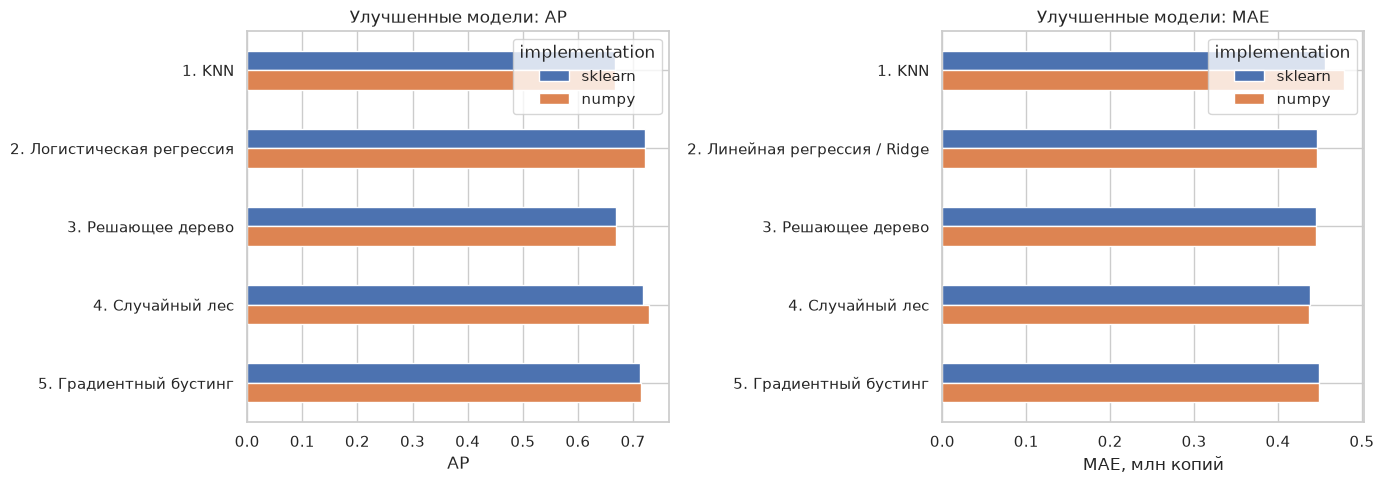

In [7]:
own_rows = []
for lab in range(1, 6):
    for implementation in ["sklearn", "numpy"]:
        subset = models.query("lab == @lab and implementation == @implementation")
        c = subset.query("task == 'c'").set_index("stage")
        r = subset.query("task == 'r'").set_index("stage")
        own_rows.append({"lab": lab, "algorithm": NAMES[lab]["c"] if lab != 2 else "Логистическая / линейная регрессия",
            "implementation": implementation, "AP baseline": c.loc["baseline", "AP"], "AP improved": c.loc["improved", "AP"],
            "MAE baseline": r.loc["baseline", "MAE"], "MAE improved": r.loc["improved", "MAE"]})
implementation_table = pd.DataFrame(own_rows)
display(implementation_table.round(4))
sk = implementation_table.query("implementation == 'sklearn'").set_index("lab")
np_models = implementation_table.query("implementation == 'numpy'").set_index("lab")
delta = pd.DataFrame({"algorithm": np_models.algorithm, "delta AP": np_models["AP improved"]-sk["AP improved"],
                      "delta MAE": np_models["MAE improved"]-sk["MAE improved"]})
display(delta.round(6))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, task in [(axes[0], "AP", "c"), (axes[1], "MAE", "r")]:
    table = models.query("task == @task and stage == 'improved'").pivot(index="lab", columns="implementation", values=metric)
    table[["sklearn", "numpy"]].plot.barh(ax=ax)
    ax.set_yticklabels([f"{lab}. {NAMES[lab][task]}" for lab in table.index])
    ax.invert_yaxis()
    ax.set(title=f"Улучшенные модели: {metric}", xlabel="AP" if task == "c" else "MAE, млн копий", ylabel="")
plt.tight_layout(); plt.show()

### Как интерпретировать расхождения реализаций
- Линейные модели практически воспроизвели прогнозы sklearn; малые отличия порядка 10⁻⁷ для вероятностей и 10⁻¹³ для регрессии объясняются численными методами.
- В KNN регрессии диагноз исходной работы: у всех 748 существенно различающихся исходных и 2515 улучшенных прогнозов совпали упорядоченные расстояния до выбранных соседей в заданном допуске. При ничьих выбирались разные игры с разными продажами. Собственный улучшенный KNN также уступает медианному Dummy.
- У CART одинаково выгодные разбиения могут давать разные структуры; после ограничения сложности результаты улучшенных моделей практически совпали.
- Случайные леса независимо генерируют выборки и подмножества признаков; небольшое преимущество одной реализации на одном тесте не доказывает общего превосходства.
- В бустинге исходные прогнозы и улучшенная регрессия практически совпали. Улучшенная классификация стохастическая, поэтому подвыборки NumPy и sklearn и итоговые вероятности различаются.

Эти наблюдения взяты из проверок и диагностики ячеек исходных работ. Результаты контрольных примеров дополняют сравнение метрик, но не являются формальным доказательством корректности всех возможных случаев.

## 5. Ограничения прогнозов и технические особенности
Во второй работе линейные модели не ограничивают прогноз снизу: отрицательные продажи физически невозможны, но математически допустимы. В пятой работе также сохраняется счётчик отрицательных прогнозов. В остальных CSV такого столбца нет — отсутствие столбца не следует подменять измеренным нулём.

В четвёртой работе OOB — дополнительная диагностика при фиксированной подготовке. У улучшенного классификатора покрытие около 99.86–99.89%; строки без OOB-прогноза исключены из OOB-метрики. Для продаж OOB не заменяет групповую CV. Метрики OOB приведены в исходном ноутбуке, а не в двух итоговых CSV.

`predict_seconds` включает предсказание и расчёт метрик на тесте. Эти одиночные замеры зависят от оборудования и нагрузки, не включают обучение и CV, поэтому строгий рейтинг скорости по ним не строится.

In [8]:
if "negative_predictions" in metrics:
    negative = metrics.loc[(metrics.task == "r") & (metrics.model != "Dummy") & metrics.negative_predictions.notna(),
                           ["lab", "algorithm", "model", "negative_predictions", "MAE", "RMSE"]].copy()
    negative["negative_predictions"] = negative.negative_predictions.astype(int)
    display(negative.round(4).reset_index(drop=True))
    if (negative.negative_predictions > 0).any():
        display(Markdown("**В данных есть отрицательные прогнозы продаж.** Они не обрезались при оценке. "
                         "Для практического применения требуется отдельно проверить подход, обеспечивающий неотрицательность."))
    else:
        display(Markdown("В моделях с сохранённым счётчиком отрицательных прогнозов не обнаружено."))

,lab,algorithm,model,negative_predictions,MAE,RMSE
0,2,Линейная регрессия / Ridge,sklearn baseline,408,0.5348,1.4714
1,2,Линейная регрессия / Ridge,sklearn improved,68,0.4468,1.4993
2,2,Линейная регрессия / Ridge,numpy baseline,408,0.5348,1.4714
3,2,Линейная регрессия / Ridge,numpy improved,68,0.4468,1.4993
4,5,Градиентный бустинг,sklearn baseline,0,0.5337,1.4908
5,5,Градиентный бустинг,sklearn improved,0,0.4486,1.5111
6,5,Градиентный бустинг,numpy baseline,0,0.5337,1.4908
7,5,Градиентный бустинг,numpy improved,0,0.4486,1.5111


**В данных есть отрицательные прогнозы продаж.** Они не обрезались при оценке. Для практического применения требуется отдельно проверить подход, обеспечивающий неотрицательность.

## 6. Итоговые выводы
Следующая ячейка находит лидеров среди **улучшенных** моделей по основным метрикам, проверяет выигрыш над Dummy и отмечает общий эффект улучшений. Это описательное сравнение на текущем holdout; параметры после просмотра отчёта не подбираются.

In [9]:
for implementation in ["sklearn", "numpy"]:
    c = models.query("task == 'c' and stage == 'improved' and implementation == @implementation")
    r = models.query("task == 'r' and stage == 'improved' and implementation == @implementation")
    best_c, best_r = c.loc[c.AP.idxmax()], r.loc[r.MAE.idxmin()]
    display(Markdown(f"**{implementation}:** лидер классификации — {best_c.algorithm}, AP={best_c.AP:.4f}; "
        f"лидер регрессии — {best_r.algorithm}, MAE={best_r.MAE:.4f} млн копий. "
        f"Его MAE ниже Dummy на {(dummy_mae-best_r.MAE)/dummy_mae*100:.2f}%."))
    losers = r.loc[r.MAE >= dummy_mae, "algorithm"].tolist()
    if losers:
        display(Markdown(f"**{implementation}:** не превзошли Dummy по MAE: {', '.join(losers)}."))
    changed = implementation_table.query("implementation == @implementation")
    improved_c = int((changed["AP improved"] > changed["AP baseline"]).sum())
    improved_r = int((changed["MAE improved"] < changed["MAE baseline"]).sum())
    display(Markdown(f"Выбранные улучшения повысили AP у **{improved_c} из 5** моделей и снизили MAE "
                     f"у **{improved_r} из 5** моделей {implementation}."))
display(Markdown("Все изученные семейства сравнивались с постоянным ориентиром и собственными бейзлайнами. "
                 "Рост качества относительно исходной модели не гарантирует преимущества над Dummy, "
                 "а усложнение алгоритма не гарантирует лучшего результата среди семейств."))

**sklearn:** лидер классификации — Логистическая регрессия, AP=0.7208; лидер регрессии — Случайный лес, MAE=0.4383 млн копий. Его MAE ниже Dummy на 3.93%.

**sklearn:** не превзошли Dummy по MAE: KNN.

Выбранные улучшения повысили AP у **5 из 5** моделей и снизили MAE у **5 из 5** моделей sklearn.

**numpy:** лидер классификации — Случайный лес, AP=0.7290; лидер регрессии — Случайный лес, MAE=0.4373 млн копий. Его MAE ниже Dummy на 4.14%.

**numpy:** не превзошли Dummy по MAE: KNN.

Выбранные улучшения повысили AP у **5 из 5** моделей и снизили MAE у **5 из 5** моделей numpy.

Все изученные семейства сравнивались с постоянным ориентиром и собственными бейзлайнами. Рост качества относительно исходной модели не гарантирует преимущества над Dummy, а усложнение алгоритма не гарантирует лучшего результата среди семейств.

### Практические границы выводов

Steam-набор синтетический, что указано автором в `data/steam/README.md`: результаты описывают генератор данных. Продажи исторические, отобраны по наличию продаж и имеют разные сроки накопления. Для внедрения нужны реальные дорелизные признаки, единый горизонт продаж и временное тестирование.

Выбор гипотез и параметров на одних CV-разбиениях может давать оптимизм. Один общий holdout не доказывает статистическую значимость различий между алгоритмами. Небольшой отрыв AP или MAE не следует трактовать как устойчивое превосходство без дополнительных разбиений и оценки неопределённости. Ограниченные сетки этой серии работ не определяют максимально достижимое качество каждого алгоритма.

### Что означают исходные файлы

В каждой `results/research-N/` находятся две таблицы:
- **`cv_experiments.csv`**: `task` (`c`/`r`), `experiment` (гипотеза), `score` или `selection_score` (средняя AP / −MAE), `std` (стандартное отклонение по fold). Для этапа с поиском параметров записана оценка лучшей конфигурации этапа, а не вся сетка.
- **`test_metrics.csv`**: `task`, `model` и тестовые метрики. Варианты: `Dummy`, `sklearn baseline`, `sklearn improved`, `numpy baseline`, `numpy improved`. AP и ROC AUC оценивают ранжирование; F1, precision, recall, balanced accuracy и accuracy — классы при фиксированном пороге. MAE/RMSE измеряются в миллионах копий; R² может быть отрицательным. `negative_predictions` присутствует в работах №2 и №5. `predict_seconds` — время предсказания вместе с вычислением метрик, без обучения.

NaN в неприменимых столбцах не означает неудачное обучение. Модели и массивы прогнозов исходных работ не сериализуются в эти CSV, графики и напечатанные результаты сохраняются в выводах ноутбуков. Этот отчёт читает готовые таблицы и не создаёт дополнительных файлов в `results/`.